# Proyecto integrador · Actividad 1 (U4): diseño experimental y línea base

**Técnicas Avanzadas de Modelado en IA, MIA 2026-5, Universidad de La Sabana.**
Equipo: Leonar Socarrás Molina, PhD, y John Jairo Serrano Cifuentes, Esp. Docente: PhD. Oscar Alberto Rodríguez Meléndez.

Este cuaderno comunica la evidencia del plan experimental; la lógica reutilizable vive en `src/flores/`, las decisiones en `configs/` y la evidencia generada en `outputs/` (estructura recomendada en la sesión U4S2). Orden de ejecución:

1. Verificar el archivo de datos (SHA-256).
2. Auditoría de calidad e inventario.
3. Grupos de fuga y partición estratificada por grupos.
4. Pruebas automáticas de la partición y de las métricas.
5. Líneas base E00 a E03 con registro en MLflow.
6. Comparación, incertidumbre y figuras.

In [1]:
import hashlib, json, subprocess, sys
from pathlib import Path
import pandas as pd
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
OUT, DATOS = RAIZ / "outputs", RAIZ / "data"
RECALCULAR = False   # True: reconstruye inventario, partición y líneas base desde cero
pd.set_option("display.precision", 4)
print(RAIZ)

/home/claude/u4a1/repo


## 1. Integridad del archivo de datos
Descarga oficial: `https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz`. El SHA-256 debe coincidir con el registrado en la hoja de datos.

In [2]:
ESPERADO = "4c54ace7911aaffe13a365c34f650e71dd5bf1be0a58b464e5a7183e3e595d9c"
tgz = DATOS / "flower_photos.tgz"
if tgz.exists():
    h = hashlib.sha256(tgz.read_bytes()).hexdigest()
    print("SHA-256 coincide:", h == ESPERADO)
else:
    print("Archivo .tgz no presente; se usa la carpeta extraída data/flower_photos")

Archivo .tgz no presente; se usa la carpeta extraída data/flower_photos


## 2. Auditoría inicial de calidad

In [3]:
if RECALCULAR:
    subprocess.run([sys.executable, str(RAIZ / "src/flores/auditoria.py"), str(DATOS / "flower_photos"), str(OUT)], check=True)
inv = pd.read_csv(OUT / "inventario_grupos.csv")
k = inv[inv.exclusion.fillna("") == ""]
lado = k[["width", "height"]].min(axis=1)
auditoria = pd.Series({
    "imágenes totales": len(inv),
    "sin línea de licencia": int((inv.exclusion == "sin_licencia").sum()),
    "etiqueta contradictoria (mismos píxeles, 2 clases)": int((inv.exclusion == "etiqueta_contradictoria").sum()),
    "imágenes usadas": len(k),
    "autores de Flickr": k.owner.nunique(),
    "copias exactas de píxeles": int(k.md5_pixels.duplicated().sum()),
    "casi monocromas (saturación < 0,08)": int((k.saturation_mean < 0.08).sum()),
    "oscuras (brillo < 50)": int((k.brightness_mean < 50).sum()),
    "sobreexpuestas (brillo > 200)": int((k.brightness_mean > 200).sum()),
    "borrosas (var. laplaciano < 50)": int((k.laplacian_var < 50).sum()),
    "ruido alto (sigma Immerkær > 15)": int((k.noise_sigma > 15).sum()),
    "lado menor < 200 px": int((lado < 200).sum()),
})
auditoria.to_frame("valor")

,valor
imágenes totales,3670
sin línea de licencia,9
"etiqueta contradictoria (mismos píxeles, 2 clases)",2
imágenes usadas,3659
autores de Flickr,1531
copias exactas de píxeles,2
"casi monocromas (saturación < 0,08)",88
oscuras (brillo < 50),149
sobreexpuestas (brillo > 200),32
borrosas (var. laplaciano < 50),21


In [4]:
pd.crosstab(k.label, (k.saturation_mean < 0.08).map({True: "casi monocroma", False: "color"}))

saturation_mean,casi monocroma,color
label,,
daisy,20,613
dandelion,49,846
roses,11,625
sunflowers,1,697
tulips,7,790


## 3. Grupos de fuga y partición
Unidad de observación independiente: el **autor de Flickr** (misma cámara, jardín o planta). Un grupo une imágenes con el mismo autor, los mismos píxeles o pHash a ≤ 6 bits; cada grupo cae completo en una sola partición.

In [5]:
if RECALCULAR:
    subprocess.run([sys.executable, str(RAIZ / "src/flores/particion.py"), str(OUT)], check=True)
rep = json.loads((OUT / "particion_reporte.json").read_text())
p = pd.read_csv(OUT / "particion.csv")
display(pd.crosstab(p.label, p.split, margins=True)[["train", "val", "test", "All"]])
pd.DataFrame({"estratificada por grupos": rep["contaminacion_por_grupos"]["test"],
              "aleatoria estratificada": rep["contaminacion_aleatoria"]["test"]})

split,train,val,test,All
label,,,,
daisy,447,93,93,633
dandelion,627,134,134,895
roses,445,96,95,636
sunflowers,488,105,105,698
tulips,557,120,120,797
All,2564,548,547,3659


,estratificada por grupos,aleatoria estratificada
n,547,549
autor_en_train,0,408
casi_duplicado_en_train,0,5


## 4. Pruebas automáticas

In [6]:
r = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no", "-p", "no:warnings", str(RAIZ / "tests")], capture_output=True, text=True, cwd=RAIZ)
print(r.stdout[-600:])

........                                                                 [100%]
8 passed in 1.24s



## 5. Líneas base E00 a E03
Cada experimento hereda de `BaseExperimento` (contrato común), ajusta solo con entrenamiento, elige hiperparámetros con validación y evalúa una sola vez en prueba. Los runs quedan en `mlruns/`.

In [7]:
if RECALCULAR:
    cfgs = ["configs/e00_mayoritaria.yaml", "configs/e01_hog_color_lr.yaml", "configs/e03_dinov2_sonda.yaml",
            "configs/e02_cnn_s11.yaml", "configs/e02_cnn_s22.yaml", "configs/e02_cnn_s33.yaml"]
    subprocess.run([sys.executable, "scripts/ejecutar.py", *cfgs], check=True, cwd=RAIZ)
filas = {}
for f in sorted(OUT.glob("E0*_resultados.json")):
    r = json.loads(f.read_text()); t = r["test"]
    filas[f.name.split("_resultados")[0]] = {
        "macro-F1": t["macro_f1"], "IC95 inf": t["macro_f1_ic95"][0], "IC95 sup": t["macro_f1_ic95"][1],
        "exactitud": t["accuracy"], "exact. balanceada": t["balanced_acc"], "log-loss": t["log_loss"],
        "ECE": t["ece"], "macro-F1 val": r["val"]["macro_f1"], "P95 ms": r["extra"].get("p95_ms")}
tabla = pd.DataFrame(filas).T
tabla

,macro-F1,IC95 inf,IC95 sup,exactitud,exact. balanceada,log-loss,ECE,macro-F1 val,P95 ms
E00,0.0787,0.0616,0.1000,0.2450,0.2000,6.4309,0.7542,0.0786,NaN
E01,0.5687,0.5032,0.6118,0.5740,0.5687,1.2156,0.1197,0.5537,10.1125
E02_s11,0.7083,0.6538,0.7417,0.7130,0.7125,0.7924,0.0823,0.7121,3.5460
E02_s22,0.7373,0.6892,0.7763,0.7441,0.7409,0.7205,0.0653,0.7053,2.7030
E02_s33,0.7088,0.6681,0.7390,0.7112,0.7097,0.7648,0.0396,0.7234,3.8571
E03,0.9866,0.9711,0.9972,0.9872,0.9856,0.0393,0.0086,0.9497,140.5128


In [8]:
cnn = tabla.loc[[i for i in tabla.index if i.startswith("E02")], ["macro-F1", "exactitud", "ECE"]]
print("E02 media ± DE entre semillas:")
print((cnn.mean().round(4).astype(str) + " ± " + cnn.std(ddof=1).round(4).astype(str)).to_string())

E02 media ± DE entre semillas:
macro-F1     0.7182 ± 0.0166
exactitud    0.7227 ± 0.0185
ECE          0.0624 ± 0.0215


In [9]:
rec = pd.DataFrame({k: {c: json.loads((OUT / f"{k}_resultados.json").read_text())["test"][f"recall_{c}"]
                        for c in ["daisy", "dandelion", "roses", "sunflowers", "tulips"]} for k in tabla.index})
rec.T  # recall por clase en prueba

,daisy,dandelion,roses,sunflowers,tulips
E00,0.0000,1.0000,0.0000,0.0000,0.0000
E01,0.4731,0.5746,0.5684,0.5524,0.6750
E02_s11,0.8172,0.7239,0.5474,0.7905,0.6833
E02_s22,0.8065,0.7313,0.5263,0.8571,0.7833
E02_s33,0.6344,0.7164,0.6632,0.8762,0.6583
E03,0.9677,1.0000,0.9684,1.0000,0.9917


## 6. Comparación pareada, control de fuga y figuras

In [10]:
import numpy as np
from flores.metricas import mcnemar_exacto
yt = p[p.split == "test"].label.map({c: i for i, c in enumerate(["daisy", "dandelion", "roses", "sunflowers", "tulips"])}).to_numpy()
ok = {k: np.load(OUT / f"{k}_proba_test.npy").argmax(1) == yt for k in tabla.index}
print("McNemar E03 vs E02_s33:", mcnemar_exacto(ok["E03"], ok["E02_s33"]))
print("McNemar E03 vs E01:   ", mcnemar_exacto(ok["E03"], ok["E01"]))
e03 = json.loads((OUT / "E03_resultados.json").read_text())["extra"]
print("Control con etiquetas permutadas (macro-F1 val):", round(e03["val_macro_f1_etiquetas_permutadas"], 4))

McNemar E03 vs E02_s33: {'solo_A_acierta': 154, 'solo_B_acierta': 3, 'p_valor': 7.062478574331563e-42}
McNemar E03 vs E01:    {'solo_A_acierta': 228, 'solo_B_acierta': 2, 'p_valor': 3.0793365812238136e-65}
Control con etiquetas permutadas (macro-F1 val): 0.2113


### Validación cruzada agrupada por autor y robustez de E03
La prueba se toca una sola vez; la CV agrupada (k = 5) usa solo entrenamiento y validación. Las perturbaciones imitan fotos de celular.

In [11]:
if RECALCULAR:
    subprocess.run([sys.executable, "src/flores/diagnostico.py", "data/flower_photos", "outputs"], check=True, cwd=RAIZ)
dg = json.loads((OUT / "E03_diagnostico.json").read_text())
cv = dg["cv_agrupada_k5"]
print(f"CV agrupada k=5: {cv['media']:.4f} ± {cv['de']:.4f}  pliegues {[round(v, 4) for v in cv['macro_f1_pliegues']]}")
pd.Series({k: v for k, v in dg["robustez_prueba_E03"].items()}).to_frame("macro-F1 / %")

CV agrupada k=5: 0.9607 ± 0.0095  pliegues [0.97, 0.9483, 0.9654, 0.9669, 0.953]


,macro-F1 / %
limpio,0.9866
desenfoque_gaussiano_r2,0.9767
jpeg_calidad_20,0.9883
subexposicion_x0.5,0.9866
baja_resolucion_x0.25,0.9544
peor_caso,0.9544
caida_relativa_peor_%,3.2599


### Predicción selectiva y comparaciones pareadas de E03
Umbral de confianza fijado en validación para precisión ≥ 99 % en lo aceptado; McNemar exacto frente a cada línea base.

In [12]:
subprocess.run([sys.executable, "src/flores/seleccion.py", "outputs"], check=True, cwd=RAIZ, capture_output=True)
sc = json.loads((OUT / "E03_seleccion_y_comparaciones.json").read_text())
display(pd.Series(sc["seleccion"]).to_frame("E03"))
pd.DataFrame(sc["mcnemar_E03_vs"]).T

,E03
precision_objetivo_val,0.9900
umbral_val,0.9020
cobertura_val,0.9124
cobertura_test,0.9598
precision_aceptadas_test,0.9981


,solo_A_acierta,solo_B_acierta,p_valor
E01,228.0,2.0,3.0793e-65
E02_s11,152.0,2.0,1.0454e-42
E02_s22,135.0,2.0,1.0853e-37
E02_s33,154.0,3.0,7.0625e-42


figuras en outputs/figuras


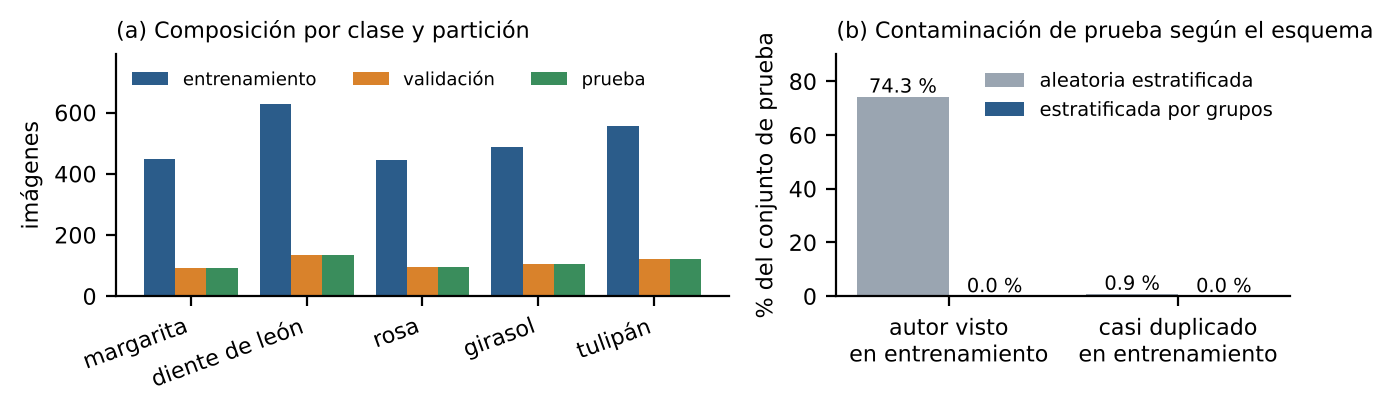

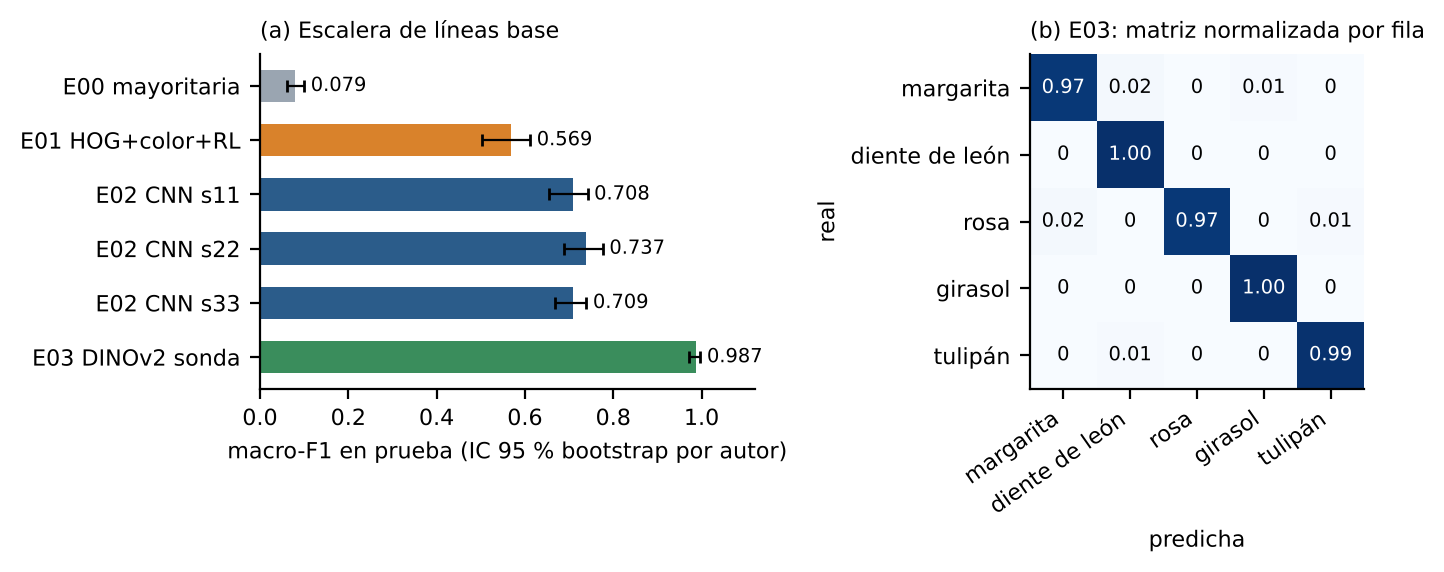

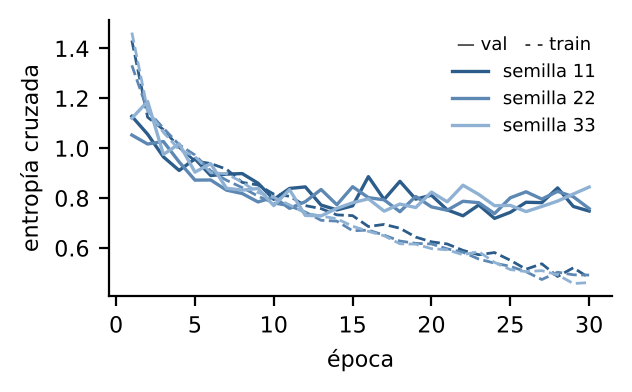

In [13]:
subprocess.run([sys.executable, "scripts/figuras.py", "outputs"], check=True, cwd=RAIZ)
from IPython.display import Image as Img
for f in ["fig1_particion.png", "fig2_lineas_base.png", "fig3_curvas_cnn.png"]:
    display(Img(filename=str(OUT / "figuras" / f), width=760))

## 7. Lectura de los resultados
La interpretación completa está en el plan experimental (PDF). Este cuaderno no selecciona modelo final con prueba: la prueba solo se usa para reportar la línea base de referencia que la Actividad 2 debe superar con el mismo protocolo.